In [1]:
#Taxi Route Revenue, Pricing & Fleet Planner
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.taxi_planner import (
    Route, MovingAverage, ExponentialSmoothing, LinearTrend,
    SeasonalNaive, equilibrium, backtest, tune_alpha, fleet_needed, mae
)

np.random.seed(42)  # reproducible notebook-level examples

In [2]:
# 
routes = {
    "Ntinda": Route("Kampala-Ntinda", [35, 40, 42, 50, 55, 60, 48, 52, 47, 45], 2000),
    "Entebbe": Route("Kampala-Entebbe", [60, 58, 65, 70, 72, 80, 75, 68, 66, 64], 5000),
    "Mukono": Route("Kampala-Mukono", [45, 47, 50, 49, 55, 62, 58, 53, 51, 50], 3000),
}

summary = []
for key, route in routes.items():
    stats = route.statistics()
    summary.append({
        "Route": route.name,
        "Fare (UGX)": route.fare,
        "Mean passengers/day": stats["mean"],
        "Variance": stats["variance"],
        "Std. deviation": stats["std_dev"],
        "10-day revenue (UGX)": route.total_revenue(),
    })
pd.DataFrame(summary).round(2)

,Route,Fare (UGX),Mean passengers/day,Variance,Std. deviation,10-day revenue (UGX)
0,Kampala-Ntinda,2000.0,47.4,48.84,6.99,948000.0
1,Kampala-Entebbe,5000.0,67.8,40.56,6.37,3390000.0
2,Kampala-Mukono,3000.0,52.0,23.80,4.88,1560000.0


In [ ]:
#Supply-demand equilibrium for Ntinda


price, quantity = equilibrium()
print(f"Equilibrium fare: UGX {price:,.0f}")
print(f"Equilibrium quantity: {quantity:.0f} passengers per trip-hour")
current_fare = routes["Ntinda"].fare
if current_fare < price:
    print(f"The current UGX {current_fare:,.0f} fare is BELOW the modelled equilibrium.")
elif current_fare > price:
    print(f"The current fare is ABOVE the modelled equilibrium.")
else:
    print("The current fare equals the modelled equilibrium.")

Equilibrium fare: UGX 2,200
Equilibrium quantity: 76 passengers per trip-hour
The current UGX 2,000 fare is BELOW the modelled equilibrium.


In [4]:
## Compare forecasters using walk-forward backtesting

model_rows = []
best_models = {}
alpha_grid = np.arange(0.1, 1.0, 0.1)

for route_key, route in routes.items():
    y = route.passengers
    alpha, alpha_score = tune_alpha(y, alpha_grid)
    models = {
        "3-day moving average": MovingAverage(),
        f"exponential smoothing (alpha={alpha:.1f})": ExponentialSmoothing(alpha),
        "linear trend": LinearTrend(),
    }
    scores = {name: backtest(y, model, first_test_index=3) for name, model in models.items()}
    best_name = min(scores, key=scores.get)
    best_models[route_key] = models[best_name]
    for name, score in scores.items():
        model_rows.append({"Route": route.name, "Model": name, "Walk-forward MAE (passengers)": score})
    model_rows.append({"Route": route.name, "Model": "Best exponential-smoothing alpha", "Walk-forward MAE (passengers)": alpha_score})

mae_table = pd.DataFrame(model_rows)
mae_table.round(2)

,Route,Model,Walk-forward MAE (passengers)
0,Kampala-Ntinda,3-day moving average,7.52
1,Kampala-Ntinda,exponential smoothing (alpha=0.9),5.88
2,Kampala-Ntinda,linear trend,7.87
3,Kampala-Ntinda,Best exponential-smoothing alpha,5.88
4,Kampala-Entebbe,3-day moving average,7.19
5,Kampala-Entebbe,exponential smoothing (alpha=0.9),4.73
6,Kampala-Entebbe,linear trend,7.71
7,Kampala-Entebbe,Best exponential-smoothing alpha,4.73
8,Kampala-Mukono,3-day moving average,5.33
9,Kampala-Mukono,exponential smoothing (alpha=0.9),3.79


In [5]:
#Forecast day 11 passenger counts and revenue

forecast_rows = []
day11_passengers = {}
for route_key, route in routes.items():
    model = best_models[route_key]
    predicted = max(0.0, float(model.predict(route.passengers, horizon=1)[0]))
    day11_passengers[route_key] = predicted
    forecast_rows.append({
        "Route": route.name,
        "Selected model": type(model).__name__,
        "Forecast passengers (day 11)": round(predicted, 2),
        "Fare (UGX)": route.fare,
        "Forecast revenue (UGX)": round(predicted * route.fare, 0),
    })
forecast_table = pd.DataFrame(forecast_rows)
forecast_table

,Route,Selected model,Forecast passengers (day 11),Fare (UGX),Forecast revenue (UGX)
0,Kampala-Ntinda,ExponentialSmoothing,45.25,2000.0,90494.0
1,Kampala-Entebbe,ExponentialSmoothing,64.23,5000.0,321137.0
2,Kampala-Mukono,ExponentialSmoothing,50.13,3000.0,150376.0


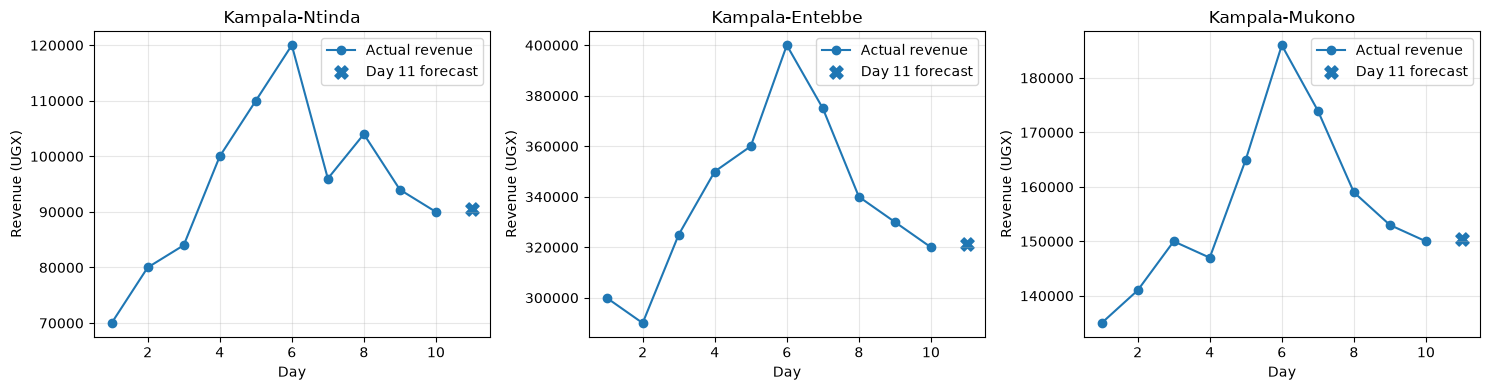

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (route_key, route) in zip(axes, routes.items()):
    actual_revenue = route.daily_revenue()
    forecast_revenue = day11_passengers[route_key] * route.fare
    ax.plot(np.arange(1, 11), actual_revenue, marker="o", label="Actual revenue")
    ax.scatter([11], [forecast_revenue], marker="X", s=90, label="Day 11 forecast")
    ax.set_title(route.name)
    ax.set_xlabel("Day")
    ax.set_ylabel("Revenue (UGX)")
    ax.ticklabel_format(style="plain", axis="y")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

In [7]:
## Fleet planning
#Each vehicle provides `14 × 8 = 112` passenger places per day under the stated assumptions. Add a 15% demand buffer and round up to a whole vehicle.

fleet_rows = []
for route_key, route in routes.items():
    predicted = day11_passengers[route_key]
    vehicles = fleet_needed(predicted, capacity=14, trips_per_vehicle=8, buffer=0.15)
    fleet_rows.append({
        "Route": route.name,
        "Day 11 forecast passengers": round(predicted, 2),
        "Buffered demand": round(predicted * 1.15, 2),
        "Capacity per vehicle/day": 14 * 8,
        "Vehicles to deploy": vehicles,
    })
pd.DataFrame(fleet_rows)

,Route,Day 11 forecast passengers,Buffered demand,Capacity per vehicle/day,Vehicles to deploy
0,Kampala-Ntinda,45.25,52.03,112,1
1,Kampala-Entebbe,64.23,73.86,112,1
2,Kampala-Mukono,50.13,57.64,112,1


In [8]:
#Extension: 60-day synthetic weekly demand

rng = np.random.default_rng(42)
days = np.arange(60)
# Monday=0 ... Sunday=6; Friday index 4, Sunday index 6
weekday_effect = np.array([0, 2, 3, 4, 12, 5, -10])
synthetic = 50 + weekday_effect[days % 7] + rng.normal(0, 2, size=60)
synthetic = np.maximum(1, synthetic)

test_start = 39  # evaluate days 40-60
moving_errors, seasonal_errors = [], []
for i in range(test_start, len(synthetic)):
    moving_errors.append(abs(synthetic[i] - MovingAverage().predict(synthetic[:i])[0]))
    seasonal_errors.append(abs(synthetic[i] - SeasonalNaive(7).predict(synthetic[:i])[0]))

extension_results = pd.DataFrame({
    "Model": ["3-day moving average", "Seasonal naive (7 days)"],
    "MAE (passengers)": [np.mean(moving_errors), np.mean(seasonal_errors)]
})
extension_results.round(2)

,Model,MAE (passengers)
0,3-day moving average,6.34
1,Seasonal naive (7 days),1.85


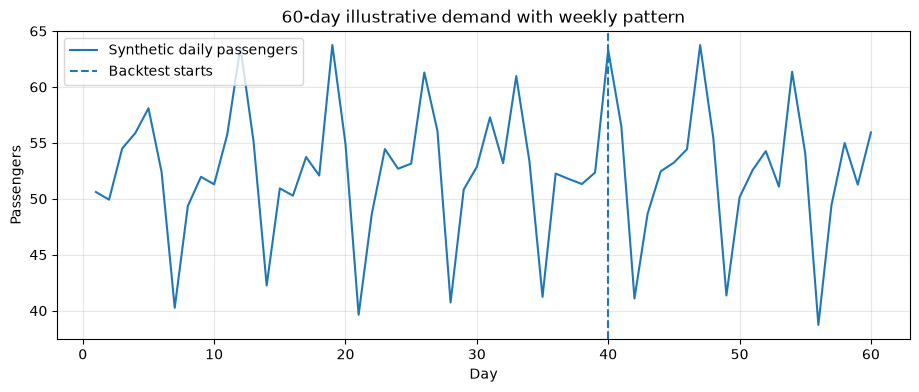

For this seeded synthetic series, seasonal-naive has lower MAE.


In [9]:
plt.figure(figsize=(11, 4))
plt.plot(days + 1, synthetic, label="Synthetic daily passengers")
plt.axvline(test_start + 1, linestyle="--", label="Backtest starts")
plt.xlabel("Day")
plt.ylabel("Passengers")
plt.title("60-day illustrative demand with weekly pattern")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

if extension_results.loc[1, "MAE (passengers)"] < extension_results.loc[0, "MAE (passengers)"]:
    print("For this seeded synthetic series, seasonal-naive has lower MAE.")
else:
    print("For this seeded synthetic series, seasonal-naive did not beat moving average; results depend on the generated noise and pattern.")

## Findings & Limitations

The equilibrium calculation gives a fare of UGX 2,200 and a quantity of 76 passengers per trip-hour. The stated Ntinda fare of UGX 2,000 is therefore below the equilibrium implied by the supplied equations. This is a model result, not proof that the association should raise fares: the curves are assumed rather than estimated from observed Kampala prices and passenger choices.

The revenue summaries show gross fare income only. They do not include fuel, repairs, wages, empty return trips, fare discounts, or other costs, so they cannot establish route profitability. The forecasting models are intentionally simple and transparent. Walk-forward MAE compares forecasts on days 4–10 without allowing future observations into earlier predictions, but only seven test points are available per route. The best model may change when more data are collected. Exponential smoothing alpha is chosen from a small grid, not from an exhaustive search.

Fleet counts assume each vehicle can complete eight one-way trips at full 14-seat capacity and that daily passenger demand can be served evenly. Real fleet planning should use passenger counts by departure and direction, journey time, peak demand, vehicle downtime, and loading rates. The 60-day series is synthetic and demonstrates why a weekday-aware seasonal forecast can help when demand repeats weekly; it is not real-world evidence about Kampala. All findings should be updated with longer, trip-level data before operational decisions.